Chemical space

In [ ]:
import pandas as pd
from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.colors import ListedColormap

selected_aeid = pd.read_csv(r"~\mlinvitrotox\data\results\models_v3\selected_aeids.csv")

aeids = selected_aeid['aeid']

In [ ]:
# the ToxCast data as a base in the background
toxcast = pd.read_csv(r"~\mlinvitrotox\data\results\models_v3\ToxCast_True_FPS.csv")
toxcast = toxcast.drop(['smiles'], axis=1)
toxcast = toxcast.rename(columns={'DTXSID': 'dtxsid'})
toxcast.head()

fp_cols = [col for col in toxcast.columns if col != 'dtxsid']

# Compute variance for each fingerprint column
fp_variances = toxcast[fp_cols].var()

# Define a threshold — very close to 0
near_zero_threshold = 0.05 # adapting to 0.1 or 0.01 changes the PCA, but the relative overlap between active/inactive stays similar

# Get list of low-variance fingerprints
near_zero_fps = fp_variances[fp_variances < near_zero_threshold].index.tolist()

# shape should be 8840, 364
df_tox = toxcast.drop(columns= near_zero_fps)
print(df_tox.shape)

(8840, 364)


In [ ]:
# extract active / inactive info from pytcpl about the assays

base_path = Path(r'~\mlinvitrotox\data\input\invitro\pytcpl')

results = []

for aeid in aeids: 
    
    aeid_path = os.path.join(base_path, f"{aeid}.parquet.gzip") 
    df = pd.read_parquet(aeid_path) 
    df = df[['dsstox_substance_id', 'hitcall_c', 'omit_flag']].copy()
    df['aeid'] = aeid  # add aeid so we can track source
    
    results.append(df)

# Combine all into a single DataFrame
final_df = pd.concat(results, ignore_index=True)

# Optionally rename columns
final_df.rename(columns={
    'dsstox_substance_id': 'dtxsid',
    'hitcall_c': 'hitcall'
}, inplace=True)

final_df = final_df.dropna(subset=['hitcall'])
keep_compound = final_df["omit_flag"].isin(["None", np.nan])
final_df = final_df[keep_compound]
final_df['hitcall'] = (final_df['hitcall'] >= 0.9).astype(int)

PCA

In [4]:
# define TP/FP/TN/FN for all test chemicals for visualization

parent_dir = Path(r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models_retrained\class") 
folders = aeids

results = []

for folder in folders:
    folder_path = parent_dir / str(folder)

    true_path = folder_path / "test_true_chemicals.csv"
    pred_path = folder_path / "FS_RandomForest" / "mb_val_structure" / "test_predictions_default.csv"

    df_true = pd.read_csv(true_path)
    df_pred = pd.read_csv(pred_path)

    combined = pd.concat([df_true, df_pred], axis=1)
    combined.rename(columns={'0': 'dtxsid'}, inplace=True)

    y_true = combined["y_true"]
    y_pred = combined["y_pred"]

    combined["category"] = [
        "TP" if yt == 1 and yp == 1 else
        "FP" if yt == 0 and yp == 1 else
        "TN" if yt == 0 and yp == 0 else
        "FN"
        for yt, yp in zip(y_true, y_pred)
    ]

    combined["aeid"] = folder

    # Keep only the columns needed for merging
    results.append(combined[["dtxsid", "aeid", "category"]])

category_df = pd.concat(results, ignore_index=True)

In [5]:
merged_df = df_tox.merge(
    final_df[['dtxsid', 'aeid', 'hitcall']], 
    on='dtxsid', how='left'
)

merged_df = merged_df.merge(
    category_df,
    on=["dtxsid", "aeid"],
    how="left"
)
merged_df

,dtxsid,33,36,40,48,58,66,67,68,70,...,14883,15556,15975,16980,17063,17606,17786,aeid,hitcall,category
0,DTXSID00190950,0,0,0,0,0,1,1,0,0,...,0,0,0,0,0,0,1,63.0,0.0,NaN
1,DTXSID00190950,0,0,0,0,0,1,1,0,0,...,0,0,0,0,0,0,1,64.0,0.0,NaN
2,DTXSID00190950,0,0,0,0,0,1,1,0,0,...,0,0,0,0,0,0,1,66.0,0.0,NaN
3,DTXSID00190950,0,0,0,0,0,1,1,0,0,...,0,0,0,0,0,0,1,68.0,0.0,NaN
4,DTXSID00190950,0,0,0,0,0,1,1,0,0,...,0,0,0,0,0,0,1,69.0,0.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
434205,DTXSID90880156,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,2843.0,0.0,NaN
434206,DTXSID90880156,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,2845.0,0.0,NaN
434207,DTXSID90880156,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,2899.0,1.0,NaN
434208,DTXSID90891560,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN


In [59]:
# Make PCA

# Fill NaN for chemicals that don't belong to any AEID
merged_df['aeid'] = merged_df['aeid'].fillna('Other')
merged_df['hitcall'] = merged_df['hitcall'].fillna(-1)

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Drop all columns that are not features for PCA
features = merged_df.drop(columns=['dtxsid', 'aeid', 'hitcall', 'category'])

# Standardize features
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# Run PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(features_scaled)

# Create a DataFrame for plotting
pca_df = pd.DataFrame(pca_result, columns=['PC1', 'PC2'])
pca_df['aeid'] = merged_df['aeid'].values
pca_df['dtxsid'] = merged_df['dtxsid'].values
pca_df['hitcall'] = merged_df['hitcall'].values
pca_df['category'] = merged_df['category'].values


In [60]:
print("PC1:", pca.explained_variance_ratio_[0])
print("PC2:", pca.explained_variance_ratio_[1])
print("Cumulative:", pca.explained_variance_ratio_.sum())

PC1: 0.08690190665313398
PC2: 0.07784295528313392
Cumulative: 0.16474486193626792


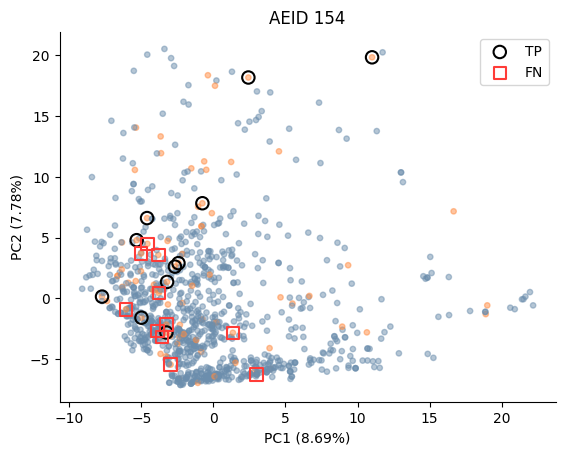

In [8]:
# Plot in paper

aeid = 154  # replace 1822

df = pca_df[pca_df['aeid'] == aeid]

cmap = ListedColormap(["#6c8ead", "#ff8c42"])  # 0 -> blue, 1 -> orange

plt.scatter(
    df["PC1"],
    df["PC2"],
    c=df["hitcall"],
    cmap=cmap,
    s=15,
    alpha=0.5
)
sns.despine()

# Highlight TP
tp = df['category'] == 'TP'
plt.scatter(
    df.loc[tp, 'PC1'],
    df.loc[tp, 'PC2'],
    s=80,
    facecolors='none',
    edgecolors='black',
    linewidth=1.5,
    label='TP'
)

# Highlight FN
fn = df['category'] == 'FN'
plt.scatter(
    df.loc[fn, 'PC1'],
    df.loc[fn, 'PC2'],
    s=80,
    facecolors='none',
    edgecolors='#ff3c38',
    linewidth=1.5,
    marker='s',
    label='FN'
)

plt.legend()
plt.xlabel('PC1 (8.69%)')
plt.ylabel('PC2 (7.78%)')
plt.title(f'AEID {aeid}')

#plt.savefig("assays154_chemical_space.svg")
plt.show()

Check the loadings of PCA

C:\Users\aischlen\AppData\Local\Temp\ipykernel_9992\1905129825.py:16: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(pca_df['PC1'], pca_df['PC2'],


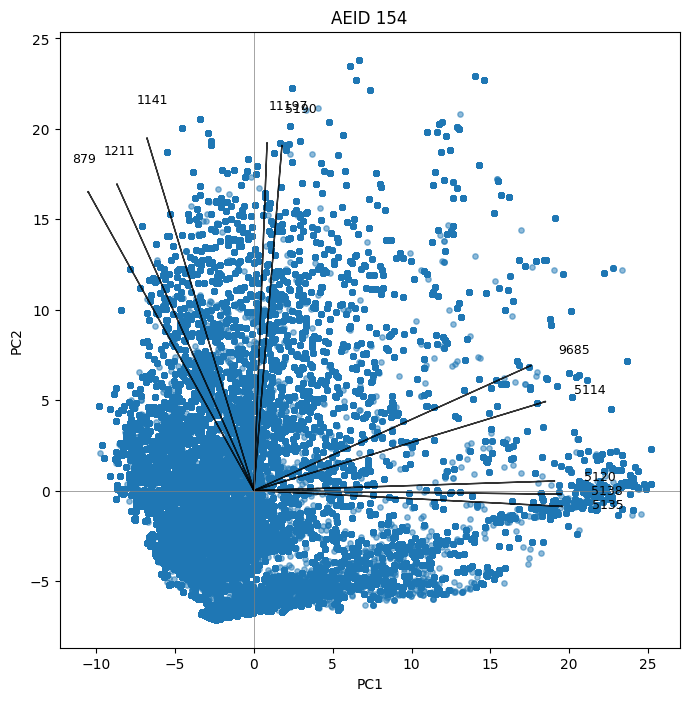

In [9]:
# Loadings for PC1 and PC2
loadings = pca.components_.T[:, :2]

# Magnitude of each loading
loading_strength = np.linalg.norm(loadings, axis=1)

# Select top 10
n_top = 10
top_idx = np.argsort(loading_strength)[-n_top:]
#importance = np.abs(loadings[:,0]) + np.abs(loadings[:,1])
#top_idx = np.argsort(importance)[-10:]

plt.figure(figsize=(8,8))

# PCA scores
plt.scatter(pca_df['PC1'], pca_df['PC2'],
            cmap='bwr',
            s=15,
            alpha=0.5)

# Scale arrows so they are visible
scale = 150

for i in top_idx:
    plt.arrow(0, 0,
              loadings[i,0]*scale,
              loadings[i,1]*scale,
              color='black',
              alpha=0.8,
              head_width=0.05)

    plt.text(loadings[i,0]*scale*1.1,
             loadings[i,1]*scale*1.1,
             features.columns[i],
             fontsize=9)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"AEID {aeid}")
plt.axhline(0, color='gray', lw=0.5)
plt.axvline(0, color='gray', lw=0.5)
plt.show()

Overlap of active and inactive class in chemicals space, using centroid distance as a spread measure

In [61]:
# List your PCA coordinate columns here
pcs = ["PC1", "PC2"]  # or ["PC1", "PC2", ..., "PC10"] adapt n_components in PCA and the column names accordingly

def normalized_centroid_distance(group):
    # Need both hitcall groups
    if group["hitcall"].nunique() < 2:
        return pd.Series({
            "centroid_distance": np.nan,
            "spread_0": np.nan,
            "spread_1": np.nan,
            "normalized_distance": np.nan
        })

    spreads = {}
    centroids = {}

    for hit in [0, 1]:
        X = group.loc[group["hitcall"] == hit, pcs].values

        # Need at least 2 compounds
        if len(X) < 2:
            return pd.Series({
                "centroid_distance": np.nan,
                "spread_0": np.nan,
                "spread_1": np.nan,
                "normalized_distance": np.nan
            })

        centroid = X.mean(axis=0)
        centroids[hit] = centroid

        # Mean distance of compounds to their centroid
        spreads[hit] = np.mean(np.linalg.norm(X - centroid, axis=1))

    centroid_distance = np.linalg.norm(
        centroids[0] - centroids[1]
    )

    avg_spread = (spreads[0] + spreads[1]) / 2

    normalized_distance = (
        centroid_distance / avg_spread
        if avg_spread > 0 else np.nan
    )

    return pd.Series({
        "centroid_distance": centroid_distance,
        "spread_0": spreads[0],
        "spread_1": spreads[1],
        "normalized_distance": normalized_distance
    })


results_centroid = (
    pca_df.groupby("aeid")
      .apply(normalized_centroid_distance)
      .reset_index()
)

print(results_centroid.head())

   aeid  centroid_distance  spread_0  spread_1  normalized_distance
0  26.0           1.596526  6.279390  7.532936             0.231174
1  46.0           2.670960  6.235771  7.350881             0.393174
2  63.0           2.001111  5.820362  5.879535             0.342073
3  64.0           1.784230  5.680990  5.541580             0.317972
4  66.0           1.669004  5.725530  5.939240             0.286161


C:\Users\aischlen\AppData\Local\Temp\ipykernel_9992\2437658889.py:56: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(normalized_centroid_distance)


What is the correlation between overlap and the model performance?

In [28]:
# performance of models

root_data_dir = Path(r"Q:\Messdaten\EXPECTmine_data\02_MLinvitroTox_PosNeg\mlinvitrotox\data\results\models\final_models_retrained\class")

metrics_list = []

for aeid in aeids:
    metrics_file = os.path.join(
        root_data_dir,
        str(aeid),
        "FS_RandomForest",
        "mb_val_structure",
        "metrics.csv"
    )

    if os.path.exists(metrics_file):
        metrics = pd.read_csv(metrics_file)

        metrics_list.append({
            "aeid": aeid,
            "accuracy": metrics.loc[0, "f1_micro"],
            "balanced_accuracy": metrics.loc[0, "balanced_accuracy"]
        })

metrics_df = pd.DataFrame(metrics_list)

In [62]:
metrics_df['aeid'] = pd.to_numeric(metrics_df['aeid'], errors='coerce').astype('Int64')
results_centroid['aeid'] = pd.to_numeric(results_centroid['aeid'], errors='coerce').astype('Int64')

scatter_df = metrics_df.merge(results_centroid[['normalized_distance', 'aeid']], on='aeid', how='left')

Text(0.5, 1.0, 'Balanced accuracy against centroid distance')

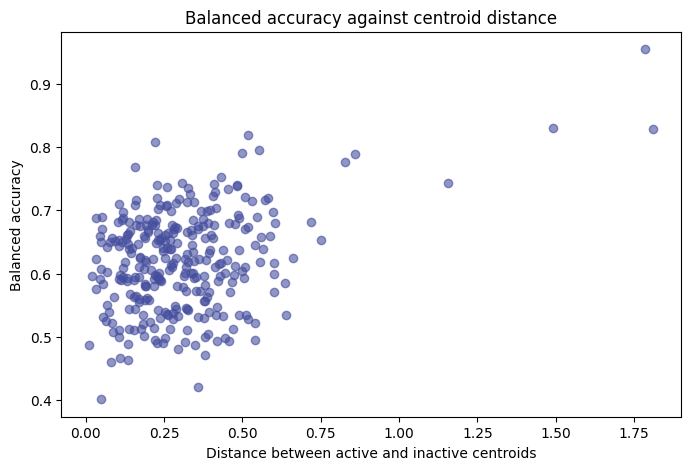

In [63]:
plt.figure(figsize=(8,5))

x = scatter_df['normalized_distance']
y = scatter_df['balanced_accuracy']

# linear trend line
#m, b = np.polyfit(x, y, 1)
#plt.plot(x, m*x + b)

plt.scatter(
    x,
    y,
    alpha=0.6,
    color='#454e9e'
)
plt.xlabel("Distance between active and inactive centroids")
plt.ylabel("Balanced accuracy")
plt.title("Balanced accuracy against centroid distance")

For assay 154 I have FP 506 be important and for assay 1822 FP 1388. Lets check how many actives/inactives have these fingerprints

In [42]:
assay_1822 = merged_df[merged_df['aeid'] == 154]
assay_1822 = assay_1822[assay_1822['category'].isna()]
active_fp = assay_1822.loc[assay_1822['hitcall'] == 1, '506'].sum()
active_total = (assay_1822['hitcall'] == 1).sum()

inactive_fp = assay_1822.loc[assay_1822['hitcall'] == 0, '506'].sum()
inactive_total = (assay_1822['hitcall'] == 0).sum()

# Calculate frequencies
active_frequency = active_fp / active_total
inactive_frequency = inactive_fp / inactive_total

# Enrichment
enrichment = active_frequency / inactive_frequency

print(f"Active with fingerprint: {active_fp}/{active_total} ({active_frequency:.2%})")
print(f"Inactive with fingerprint: {inactive_fp}/{inactive_total} ({inactive_frequency:.2%})")
print(f"Enrichment: {enrichment:.2f}x")


Active with fingerprint: 45/62 (72.58%)
Inactive with fingerprint: 211/687 (30.71%)
Enrichment: 2.36x
